# Bab 7 — *Support Vector Machine* dan Metode Kernel

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 7
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_7`)
**Direproduksi dan dijelaskan oleh:** Tarannia Raisha Putri — NIM 101032300231 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 7.1 | Pengantar SVM | `SVC(kernel="linear")`, `SVR`, `DecisionBoundaryDisplay` |
| 7.2 | Fungsi Kernel dan Penerapannya | `SVC(kernel="poly" / "rbf")` |
| 7.3 | *Tuning* Parameter SVM | `GridSearchCV` atas `C`, `kernel`, `degree` |
| 7.4 | SVM di Ruang Berdimensi Tinggi | `make_classification` (1.000 fitur), `PCA` |
| 7.5 | Mengevaluasi Model SVM | `SVC(probability=True)`, `roc_curve`, `auc` |
| 7.6 | Latihan Praktis SVM | SVC linear, *grid search* pada Breast Cancer, batas keputusan RBF |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 7.6 memakai solusi resmi dari notebook *Exercise Solutions* di repositori.

## Gambaran Umum Bab

*Support Vector Machine* (SVM) memandang klasifikasi secara geometris. Di antara semua *hyperplane* yang memisahkan dua kelas, SVM memilih yang memiliki **margin terbesar**, yaitu "jalan" terlebar di antara kelas-kelas. Hanya titik latih yang berada di tepi atau di dalam jalan itu, yaitu **support vector**, yang menentukan solusi. Melalui **kernel trick**, mekanisme yang sama menghasilkan batas non-linear dengan memetakan data secara implisit ke ruang fitur yang lebih kaya, tanpa pernah menghitung pemetaan itu.

Bab ini memperkenalkan klasifikasi SVM linear dan regresi SVM (SVR), membandingkan kernel linear, polinomial, dan RBF, men-*tuning* parameter regularisasi `C` dan pilihan kernel dengan *grid search*, menerapkan SVM linear pada dataset "lebar" yang fiturnya lebih banyak daripada sampel latihnya, dan mengevaluasi SVM dengan estimasi peluang serta kurva ROC. Dalam *pipeline* ML, ini adalah tahap *pemodelan dan pemilihan model*. Bab ini dibangun di atas alat evaluasi dari Bab 4 dan 6 serta gagasan regularisasi dari Bab 5 (di sini, `C` mengendalikan seberapa besar pelanggaran margin yang ditoleransi).

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.5
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 7.1 — Pengantar SVM

**Tujuan.** Melatih *classifier* SVM berkernel linear pada Iris, lalu mem-fit regresor SVM (SVR) berkernel RBF dan memvisualisasikan permukaan prediksinya atas dua fitur.

### Teori

**Intuisi.** Jika dua kelas dapat dipisahkan oleh sebuah garis, ada tak terhingga banyaknya garis yang bisa melakukannya. SVM memilih garis yang **sejauh mungkin dari titik-titik terdekat kedua kelas**, dengan intuisi bahwa margin pengaman yang lebar akan bergeneralisasi lebih baik pada titik baru. Data nyata saling bertumpang tindih, sehingga SVM *soft-margin* mengizinkan sebagian titik berada di dalam margin atau di sisi yang salah, dengan biaya yang dikendalikan `C`. `C` besar berarti hanya sedikit pelanggaran yang ditoleransi (margin sempit yang mengikuti data latih dengan ketat). `C` kecil berarti lebih banyak pelanggaran diizinkan (margin lebih lebar dan lebih halus).

**Matematika (klasifikasi).** Untuk label $y_i\in\{-1,+1\}$ dan fungsi keputusan $f(\mathbf{x})=\mathbf{w}^\top\mathbf{x}+b$, lebar marginnya adalah $2/\lVert\mathbf{w}\rVert$. Masalah primal *soft-margin* adalah
$$\min_{\mathbf{w},b,\boldsymbol\xi}\ \frac12\lVert\mathbf{w}\rVert^2+C\sum_{i=1}^{n}\xi_i\quad\text{s.t.}\quad y_i(\mathbf{w}^\top\mathbf{x}_i+b)\ge1-\xi_i,\ \ \xi_i\ge0,$$
dengan variabel *slack* $\xi_i$ mengukur seberapa jauh titik $i$ melanggar margin. Secara ekuivalen, masalah ini meminimalkan **hinge loss** $\sum_i\max(0,1-y_if(\mathbf{x}_i))$ ditambah penalti L2. Bentuk dual-nya bergantung pada data hanya melalui hasil kali dalam (*inner product*):
$$\max_{\boldsymbol\alpha}\ \sum_i\alpha_i-\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\,K(\mathbf{x}_i,\mathbf{x}_j)\quad\text{s.t.}\ 0\le\alpha_i\le C,\ \sum_i\alpha_iy_i=0,$$
dengan $K(\mathbf{x}_i,\mathbf{x}_j)=\mathbf{x}_i^\top\mathbf{x}_j$ untuk kernel linear. Prediksinya adalah $f(\mathbf{x})=\sum_i\alpha_iy_iK(\mathbf{x}_i,\mathbf{x})+b$, dan hanya titik dengan $\alpha_i>0$ (**support vector**) yang berkontribusi.

**Matematika (regresi, SVR).** SVR mem-fit sebuah fungsi dan mengabaikan galat yang lebih kecil dari $\varepsilon$ (**tabung ε-insensitive**):
$$\min\ \frac12\lVert\mathbf{w}\rVert^2+C\sum_i(\xi_i+\xi_i^*)\quad\text{s.t.}\quad y_i-f(\mathbf{x}_i)\le\varepsilon+\xi_i,\ \ f(\mathbf{x}_i)-y_i\le\varepsilon+\xi_i^*,\ \ \xi_i,\xi_i^*\ge0.$$
Titik di dalam tabung tidak berpengaruh, dan *support vector* adalah titik yang berada di tepi atau di luar tabung.

**Cara scikit-learn mengimplementasikannya.**

* `SVC(C=1.0, kernel="rbf", degree=3, gamma="scale", coef0=0.0, probability=False, decision_function_shape="ovr")` membungkus **libsvm**, yang menyelesaikan bentuk dual dengan algoritme bertipe SMO. Untuk $K>2$ kelas, ia melatih $K(K-1)/2$ SVM biner **one-vs-one** dan menggabungkan suaranya. Setelah `fit` tersedia `support_vectors_`, `n_support_` (per kelas), dan `dual_coef_` ($\alpha_iy_i$).
* `SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale")` memakai solver yang sama untuk masalah ε-insensitive.
* `DecisionBoundaryDisplay.from_estimator(estimator, X, response_method=...)` mengevaluasi estimator pada grid yang mencakup rentang `X` lalu menggambar hasilnya. Untuk regresor dengan `response_method="predict"`, ia menampilkan nilai prediksi sebagai kontur berisi warna.

**Asumsi, kelebihan, keterbatasan.**

* Kelebihan: solusi margin maksimum bergeneralisasi dengan baik, solusinya *sparse* (hanya *support vector* yang berpengaruh), bekerja di dimensi tinggi, dan kernel membuatnya fleksibel.
* Keterbatasan: biaya pelatihan kira-kira antara $O(n^2)$ dan $O(n^3)$, sehingga tidak praktis untuk lebih dari puluhan ribu sampel. Sangat sensitif terhadap penskalaan fitur. Tidak menghasilkan peluang secara bawaan. `C` dan parameter kernel perlu di-*tuning*.
* Gunakan untuk dataset kecil hingga menengah, dengan banyak fitur, dan batas yang jelas meskipun mungkin non-linear.

### Kode

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Pembagian 70/30 -> 105 bunga latih / 45 bunga uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [3]:
# Classifier margin maksimum berkernel linear (one-vs-one untuk 3 kelas)
svm_classifier = SVC(kernel='linear')

svm_classifier.fit(X_train, y_train)

y_pred = svm_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_df

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


In [4]:
# Jumlah support vector per kelas (tambahan)
print("support vector per kelas [setosa, versicolor, virginica]:", svm_classifier.n_support_,
      "| total:", svm_classifier.n_support_.sum(), "dari", len(X_train), "titik latih")

support vector per kelas [setosa, versicolor, virginica]: [ 3 10  8] | total: 21 dari 105 titik latih


**Interpretasi output.**

* SVM linear mengklasifikasikan **93,3 %** dari 45 bunga uji dengan benar (42/45).
* Setosa sempurna (18/18). Ketiga kesalahan terjadi antara versicolor (*recall* 0.833, yaitu 10 dari 12) dan virginica (*precision* 0.875).
* Pengecekan tambahan menunjukkan betapa *sparse* solusinya: hanya **21 dari 105 titik latih** yang menjadi *support vector* (3 setosa, 10 versicolor, 8 virginica). Model sepenuhnya ditentukan oleh 21 titik itu, dan menggeser titik latih lain mana pun (tanpa melintasi margin) tidak akan mengubahnya.
* Setosa hanya membutuhkan 3 *support vector* karena letaknya jauh dari kelas lain. Versicolor dan virginica bertumpang tindih, sehingga banyak titiknya berada di dekat batas.

In [5]:
# Regresi epsilon-insensitive berkernel RBF pada dua fitur pertama
svm_regressor = SVR(kernel='rbf')

svm_regressor.fit(X_train[:, :2], y_train)

y_pred_reg = svm_regressor.predict(X_test[:, :2])

from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


In [6]:
from sklearn.metrics import r2_score

# R^2 dan support vector SVR (tambahan)
print(f"R^2: {r2_score(y_test, y_pred_reg):.3f} | support vector: {len(svm_regressor.support_)} dari {len(X_train)}")
print(f"rentang prediksi: {y_pred_reg.min():.2f} hingga {y_pred_reg.max():.2f}")

R^2: 0.721 | support vector: 70 dari 105
rentang prediksi: -0.17 hingga 2.06


**Interpretasi output.** Buku memakai SVR pada label kelas 0/1/2 seolah-olah label itu bilangan, hanya dengan *sepal length* dan *sepal width*. **MSE** ujinya **0.20** dan pengecekan tambahan memberi **$R^2 = 0.72$**, sehingga regresor menangkap sebagian besar variasi label. Prediksinya berkisar dari −0.17 hingga 2.06, nilai kontinu yang perlu dibulatkan agar menjadi kelas. Cara ini hanya berhasil karena spesiesnya kebetulan berurutan menurut ukuran (setosa < versicolor < virginica). Secara umum, memperlakukan label kelas sebagai target regresi memaksakan urutan yang mungkin tidak bermakna. **70 dari 105** titik latih adalah *support vector*, yaitu titik yang berada di tepi atau di luar tabung ε = 0.1.

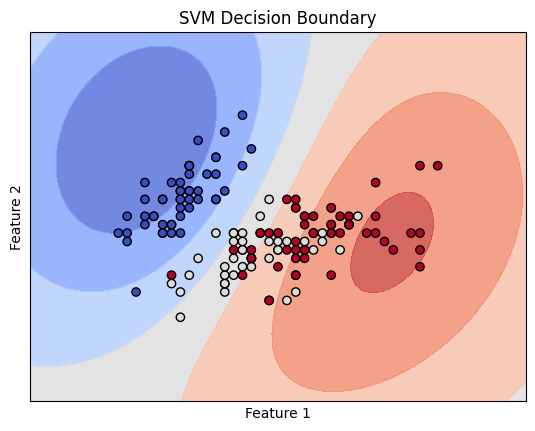

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import DecisionBoundaryDisplay

# Grid yang mencakup dua fitur pertama, dengan bantalan 1 satuan
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Titik grid ditambah dua kolom nol (hanya dua kolom pertama yang dipakai di bawah)
grid_points = np.c_[xx.ravel(), yy.ravel(), np.zeros((xx.ravel().shape[0], 2))]

# Kontur berisi warna dari nilai prediksi SVR di rentang grid
fig, ax = plt.subplots()
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor,
    grid_points[:, :2],
    response_method="predict",
    plot_method="contourf",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax
)

# Tumpangkan ke-150 bunga, diwarnai per spesies
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
ax.set_title("SVM Decision Boundary")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xticks(())
ax.set_yticks(())
plt.show()

**Interpretasi output.** Karena estimatornya adalah *regresor*, wilayah berwarna bukanlah wilayah kelas. Wilayah itu adalah **pita nilai prediksi**: biru tua ≈ 0 (mirip setosa), abu-abu ≈ 1, merah tua ≈ 2 (mirip virginica). Feature 1 adalah *sepal length* dan Feature 2 adalah *sepal width* (tanda sumbu disembunyikan oleh kode buku). Setosa (titik biru) berada di wilayah biru, pada sepal yang pendek dan lebar. Versicolor (putih) dan virginica (merah) bercampur di separuh kanan bawah, itulah sebabnya permukaan prediksi hanya berubah secara bertahap di sana. Bentuk pita yang elips berasal dari kernel RBF: setiap *support vector* hanya memengaruhi lingkungannya, sehingga jauh dari data latih prediksi kembali ke arah intersep (≈ 1), yang menghasilkan area abu-abu di pojok-pojok jauh plot.

### Poin Penting
* SVM memaksimalkan margin $2/\lVert\mathbf{w}\rVert$ sambil membayar `C` per satuan *slack*. Hanya *support vector* (21 dari 105 di sini) yang mendefinisikan model.
* `SVC` melatih *classifier one-vs-one* untuk masalah multikelas. SVM linear mencapai 93,3 % pada Iris.
* `SVR` mem-fit tabung ε-insensitive. Diterapkan pada label kelas yang berurutan, hasilnya MSE 0.20 / $R^2$ 0.72, tetapi label secara umum bukan bilangan.

## Resep 7.2 — Fungsi Kernel dan Penerapannya

**Tujuan.** Membandingkan kernel polinomial dan RBF dengan kernel linear dari Resep 7.1 pada Iris, serta memvisualisasikan bagaimana setiap kernel membentuk batas keputusan dalam dua dimensi.

### Teori

**Intuisi.** Sebagian dataset tidak dapat dipisahkan oleh garis lurus di ruang aslinya, tetapi menjadi terpisah secara linear setelah ditransformasi. Misalnya, menambahkan $x^2$ sebagai fitur dapat mengubah "cincin di sekitar pusat" menjadi sesuatu yang dapat dipisahkan. Menghitung transformasi seperti itu secara eksplisit bisa mahal, bahkan berdimensi tak hingga. **Kernel trick** memanfaatkan fakta bahwa dual SVM (Resep 7.1) hanya membutuhkan **hasil kali dalam** antartitik, sehingga $\mathbf{x}_i^\top\mathbf{x}_j$ dapat diganti dengan fungsi kernel $K(\mathbf{x}_i,\mathbf{x}_j)=\phi(\mathbf{x}_i)^\top\phi(\mathbf{x}_j)$ yang langsung menghitung hasil kali dalam di ruang hasil transformasi.

**Matematika.** Kernel yang tersedia di `SVC`:

| Kernel | Rumus | Ruang fitur implisit |
|---|---|---|
| linear | $K(\mathbf{x},\mathbf{z})=\mathbf{x}^\top\mathbf{z}$ | ruang asli |
| polinomial | $K(\mathbf{x},\mathbf{z})=(\gamma\,\mathbf{x}^\top\mathbf{z}+r)^d$ | semua monomial hingga derajat $d$ (untuk $r>0$) |
| RBF (Gaussian) | $K(\mathbf{x},\mathbf{z})=\exp(-\gamma\lVert\mathbf{x}-\mathbf{z}\rVert^2)$ | berdimensi tak hingga |
| sigmoid | $K(\mathbf{x},\mathbf{z})=\tanh(\gamma\,\mathbf{x}^\top\mathbf{z}+r)$ | (tidak selalu kernel yang valid) |

Di sini $\gamma>0$ mengatur skala kernel, $r$ adalah `coef0`, dan $d$ adalah `degree`. Kernel yang valid harus menghasilkan matriks Gram yang semi-definit positif (syarat Mercer). Untuk RBF, $\gamma$ mengendalikan lokalitas: $\gamma$ besar berarti setiap *support vector* hanya memengaruhi lingkungan yang kecil (batas berkelok-kelok, risiko *overfitting*), dan $\gamma$ kecil berarti batas yang halus. Fungsi keputusannya menjadi $f(\mathbf{x})=\sum_i\alpha_iy_iK(\mathbf{x}_i,\mathbf{x})+b$, yaitu jumlah berbobot dari kemiripan terhadap *support vector*.

**Cara scikit-learn mengimplementasikannya.** `SVC(kernel="poly", degree=3, gamma="scale", coef0=0.0)` dan `SVC(kernel="rbf", gamma="scale")`. `gamma="scale"` (default) menetapkan $\gamma=1/(p\cdot\mathrm{Var}(X))$, dengan $p$ jumlah fitur dan $\mathrm{Var}(X)$ variansi seluruh nilai input. Perhatikan bahwa dengan `coef0=0` default, kernel polinomial menjadi $(\gamma\mathbf{x}^\top\mathbf{z})^3$, yang hanya berisi suku derajat 3 tanpa suku berderajat lebih rendah. libsvm menyimpan evaluasi kernel dalam *cache* (`cache_size=200` MB).

**Asumsi, kelebihan, keterbatasan.**

* RBF adalah default yang lazim untuk masalah non-linear, dan `C` serta `gamma` harus di-*tuning* bersama.
* Kernel polinomial sensitif terhadap skala fitur (memangkatkan bilangan besar) dan terhadap `coef0`.
* Kernel membuat SVM fleksibel tetapi lebih sulit ditafsirkan, karena tidak ada bobot fitur eksplisit untuk kernel non-linear.

### Kode

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [9]:
# Kernel polinomial kubik (secara default gamma="scale", coef0=0)
svm_poly = SVC(kernel='poly', degree=3)

svm_poly.fit(X_train, y_train)

y_pred_poly = svm_poly.predict(X_test)

accuracy_poly = accuracy_score(y_test, y_pred_poly)
report_poly = classification_report(y_test, y_pred_poly, output_dict=True)
report_df_poly = pd.DataFrame(report_poly).transpose()

styled_df_poly = (report_df_poly
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
styled_df_poly

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


**Interpretasi output.** Kernel polinomial kubik mencapai **95,6 %** (43/45), satu bunga benar lebih banyak daripada kernel linear. Kedua kesalahannya adalah versicolor yang diprediksi sebagai virginica: *recall* versicolor 0.833, tetapi setiap bunga yang *diprediksi* versicolor benar (*precision* 1.000), dan *recall* virginica 1.000.

In [10]:
# Kernel Gaussian (RBF) dengan default C = 1 dan gamma = "scale"
svm_rbf = SVC(kernel='rbf')

svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
report_rbf = classification_report(y_test, y_pred_rbf, output_dict=True)
report_df_rbf = pd.DataFrame(report_rbf).transpose()

styled_df_rbf = (report_df_rbf
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
styled_df_rbf

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


In [11]:
# Support vector per kelas untuk setiap kernel (tambahan)
for name, m in [("linear", svm_classifier), ("poly", svm_poly), ("rbf", svm_rbf)]:
    print(f"{name:>6}: support vector per kelas = {m.n_support_}, total = {m.n_support_.sum()}")

linear: support vector per kelas = [ 3 10  8], total = 21
  poly: support vector per kelas = [3 6 5], total = 14
   rbf: support vector per kelas = [ 6 23 19], total = 48


**Interpretasi output.**

* Dengan pengaturan default, kernel RBF adalah **yang terlemah dari ketiganya, 91,1 %** (41/45). Ia salah mengklasifikasikan tiga virginica sebagai versicolor (*recall* virginica 0.800) dan satu versicolor sebagai virginica.
* Pengecekan tambahan menunjukkan RBF juga memakai *support vector* paling banyak (**48**, dibanding 21 untuk linear dan 14 untuk poly). Dengan `C=1` marginnya lunak dan lebar, sehingga banyak titik jatuh di dalamnya.
* Urutan poly > linear > RBF pada 45 bunga uji hanya mencerminkan 1–2 sampel, bukan kebenaran umum tentang kernel-kernel itu. Resep 7.3 men-*tuning* `C` dengan benar.

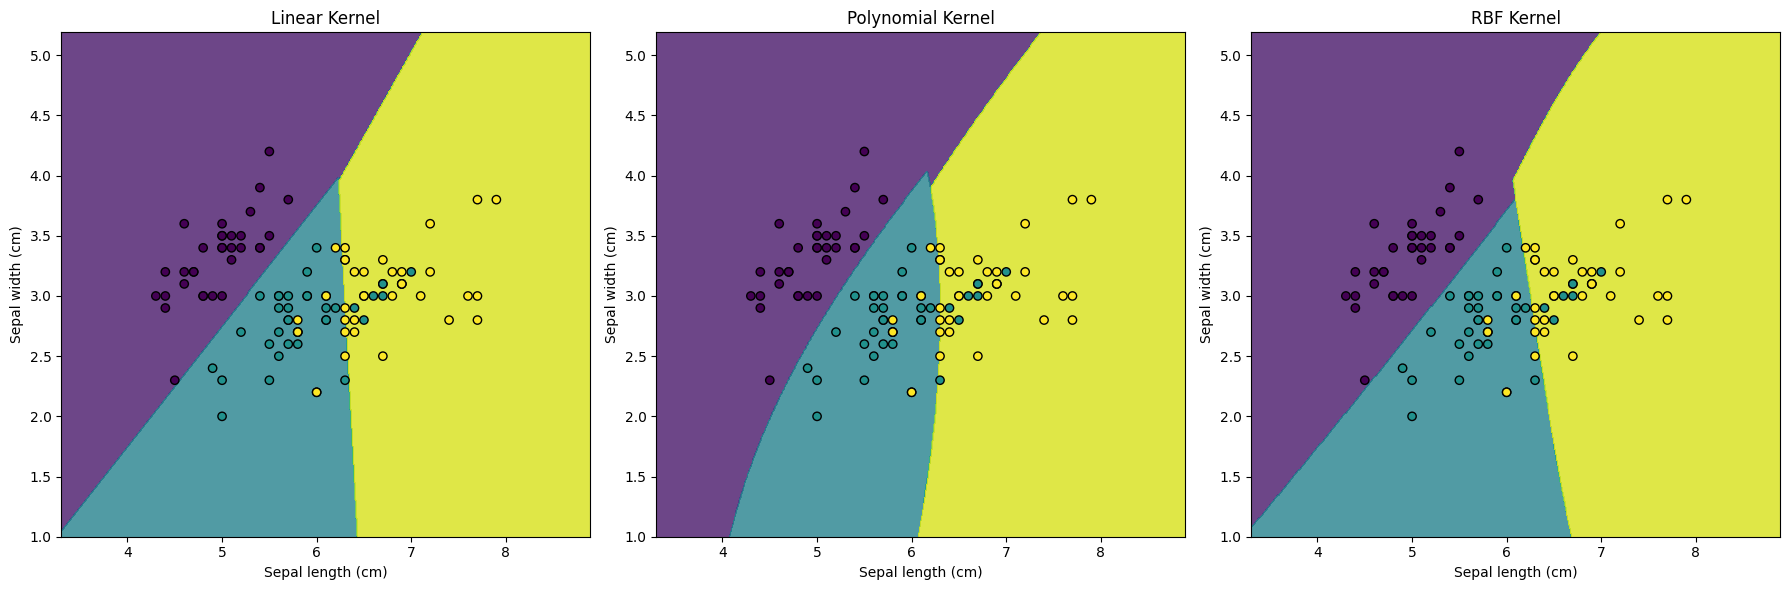

In [12]:
# Grid 2-D atas dua fitur pertama (sepal length, sepal width)
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Fit ulang setiap kernel hanya dengan dua fitur yang diplot
X_train_2d = X_train[:, :2]

svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

# Kelas prediksi di setiap titik grid
Z_linear = svm_linear_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_poly = svm_poly_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_rbf = svm_rbf_2d.predict(np.c_[xx.ravel(), yy.ravel()])

Z_linear = Z_linear.reshape(xx.shape)
Z_poly = Z_poly.reshape(xx.shape)
Z_rbf = Z_rbf.reshape(xx.shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].contourf(xx, yy, Z_linear, alpha=0.8)
axes[0].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[0].set_title("Linear Kernel")
axes[0].set_xlabel("Sepal length (cm)")  # (tambahan)
axes[0].set_ylabel("Sepal width (cm)")  # (tambahan)

axes[1].contourf(xx, yy, Z_poly, alpha=0.8)
axes[1].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[1].set_title("Polynomial Kernel")
axes[1].set_xlabel("Sepal length (cm)")  # (tambahan)
axes[1].set_ylabel("Sepal width (cm)")  # (tambahan)

axes[2].contourf(xx, yy, Z_rbf, alpha=0.8)
axes[2].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[2].set_title("RBF Kernel")
axes[2].set_xlabel("Sepal length (cm)")  # (tambahan)
axes[2].set_ylabel("Sepal width (cm)")  # (tambahan)

plt.tight_layout()
plt.show()

> **Catatan:** Enam baris `set_xlabel`/`set_ylabel` yang ditandai `# (tambahan)` tidak ada di buku. Baris-baris itu hanya memberi label sumbu. (Komentar di buku menyebut "class probabilities", padahal `predict` mengembalikan label kelas, dan itulah yang ditampilkan wilayah berwarna.)

In [13]:
# Seberapa baik model 2 fitur? (tambahan)
for name, m in [("linear", svm_linear_2d), ("poly", svm_poly_2d), ("rbf", svm_rbf_2d)]:
    print(f"{name:>6}: akurasi latih = {m.score(X_train_2d, y_train):.3f}, akurasi uji = {m.score(X_test[:, :2], y_test):.3f}")

linear: akurasi latih = 0.810, akurasi uji = 0.800
  poly: akurasi latih = 0.810, akurasi uji = 0.778
   rbf: akurasi latih = 0.838, akurasi uji = 0.800


**Interpretasi output.**

* Dengan hanya *sepal length* dan *width*, ketiga kernel memisahkan **setosa** (ungu, kiri atas: sepal pendek dan lebar) dengan bersih, memakai tepi lurus (linear) atau tepi yang sedikit melengkung (poly, RBF).
* Batas **versicolor/virginica** berupa garis hampir vertikal di sekitar *sepal length* 6–6,5 cm pada ketiga panel. Kernel polinomial sedikit melengkungkannya dan kernel RBF menghasilkan tepi yang menekuk, tetapi kedua kelas sangat bercampur dalam tampilan 2-D ini dan tidak ada kernel yang dapat mengurainya.
* Pengecekan tambahan mengukurnya: akurasi uji turun menjadi **0.800 (linear), 0.778 (poly), dan 0.800 (RBF)**, dibanding 91–96 % dengan keempat fitur. Pilihan kernel jauh kurang penting daripada memiliki fitur yang informatif (ukuran petal).

### Poin Penting
* Kernel mengganti hasil kali dalam dengan fungsi kemiripan, sehingga SVM dapat mempelajari batas non-linear tanpa pemetaan fitur eksplisit.
* Pada Iris dengan pengaturan default: poly 95,6 % > linear 93,3 % > RBF 91,1 %. Selisihnya hanya 1–2 bunga, dan RBF memakai *support vector* paling banyak (48).
* Dengan fitur yang kurang informatif (hanya sepal), setiap kernel turun ke sekitar 78–80 %, jadi kualitas fitur lebih menentukan daripada pilihan kernel.

## Resep 7.3 — *Tuning* Parameter SVM

**Tujuan.** Menemukan nilai yang baik untuk `C`, kernel, dan derajat polinomial dengan *grid search* ber-*cross-validation*, serta memvisualisasikan bagaimana akurasi *cross-validation* bergantung pada `C` untuk kernel RBF.

### Teori

**Intuisi.** `C` menetapkan harga pelanggaran margin. `C` kecil memberi margin yang lebar dan toleran (risiko *underfitting*), sedangkan `C` besar memberi margin sempit yang berusaha mengklasifikasikan setiap titik latih dengan benar (risiko *overfitting*). Parameter kernel (`degree` untuk polinomial, `gamma` untuk RBF) menentukan seberapa fleksibel batasnya. Semuanya saling berinteraksi, sehingga di-*tuning* bersama dengan *cross-validation*, persis seperti di Resep 4.3.

**Matematika.** *Grid search* mengevaluasi $\mathrm{CV}(\theta)=\frac1K\sum_{f=1}^{K}\mathrm{Acc}(\hat h_\theta^{(-f)},F_f)$ untuk setiap $\theta$ dalam hasil kali Kartesius nilai-nilai kandidat dan mengembalikan $\arg\max_\theta\mathrm{CV}(\theta)$. Di sini $\Theta=\{0.1,1,10\}\times\{\text{linear},\text{rbf},\text{poly}\}\times\{2,3,4\}$, sehingga ada 27 pengaturan × 5 *fold* = 135 kali fitting. Perhatikan bahwa `degree` **diabaikan** oleh kernel linear dan RBF, sehingga 18 dari 27 pengaturan adalah duplikat (hanya 3 + 3 + 9 = 15 model yang berbeda).

**Cara scikit-learn mengimplementasikannya.** `GridSearchCV(SVC(), param_grid, cv=5)` memakai CV stratified 5-fold dan akurasi (`score` default *classifier*). Skor CV rata-rata yang seri berbagi peringkat 1, dan `best_params_` adalah pengaturan seri **pertama** menurut urutan grid. Resep kemudian membangun `SVC(**best_params)` baru dan mem-fit-nya pada data latih, yang setara dengan `grid_search.best_estimator_` (sudah di-fit ulang karena `refit=True`).

**Asumsi, kelebihan, keterbatasan.**

* Grid sebaiknya mencakup beberapa orde besaran untuk `C` (dan `gamma`), seperti pada eksperimen kedua dengan `np.logspace(-4, 4, 10)`.
* Pada dataset kecil, banyak pengaturan yang seri, jadi pilih model paling sederhana di antara yang seri.
* SVM sebaiknya di-*tuning* pada fitur yang sudah diskalakan. Iris memakai satuan yang sebanding (cm), sehingga hal ini masih dapat diterima di sini.

### Kode

In [14]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [15]:
# 3 x 3 x 3 = 27 pengaturan (degree hanya berpengaruh untuk kernel poly)
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# CV stratified 5-fold untuk setiap pengaturan
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

# Fit ulang SVC baru dengan pengaturan pemenang pada seluruh data latih
best_model = SVC(**best_params)
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

styled_report_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


In [16]:
# Papan peringkat: berapa pengaturan yang seri di posisi pertama? (tambahan)
res = pd.DataFrame(grid_search.cv_results_)
res["params"] = res["params"].astype(str)
with pd.option_context("display.max_colwidth", None):
    display(res[["params", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score").head(10))

,params,mean_test_score,rank_test_score
12,"{'C': 1, 'degree': 3, 'kernel': 'linear'}",0.990476,1
11,"{'C': 1, 'degree': 2, 'kernel': 'poly'}",0.990476,1
9,"{'C': 1, 'degree': 2, 'kernel': 'linear'}",0.990476,1
15,"{'C': 1, 'degree': 4, 'kernel': 'linear'}",0.990476,1
8,"{'C': 0.1, 'degree': 4, 'kernel': 'poly'}",0.990476,1
25,"{'C': 10, 'degree': 4, 'kernel': 'rbf'}",0.990476,1
22,"{'C': 10, 'degree': 3, 'kernel': 'rbf'}",0.990476,1
19,"{'C': 10, 'degree': 2, 'kernel': 'rbf'}",0.990476,1
20,"{'C': 10, 'degree': 2, 'kernel': 'poly'}",0.980952,9
5,"{'C': 0.1, 'degree': 3, 'kernel': 'poly'}",0.980952,9


**Interpretasi output.**

* *Grid search* melaporkan **`C=0.1, degree=4, kernel='poly'`** dengan akurasi CV **0.99**.
* Papan peringkat menunjukkan "pemenang" ini adalah salah satu dari **delapan pengaturan yang seri di 0.9905**: linear dengan `C=1` (tiga baris duplikat yang hanya berbeda pada `degree` yang tidak relevan), poly dengan `C=1, degree=2`, poly dengan `C=0.1, degree=4`, dan RBF dengan `C=10` (tiga duplikat). Pengaturan ini dilaporkan hanya karena muncul pertama menurut urutan grid. Pengaturan berikutnya bernilai 0.9810, satu bunga lebih rendah.
* Pada data uji, model hasil *tuning* mencapai **0.93** (42/45), dengan pola per kelas yang sama seperti SVM linear tanpa *tuning* di Resep 7.1.
* Skor CV 0.99 vs skor uji 0.93 adalah optimisme akibat memilih nilai maksimum dari banyak estimasi CV yang berisik.

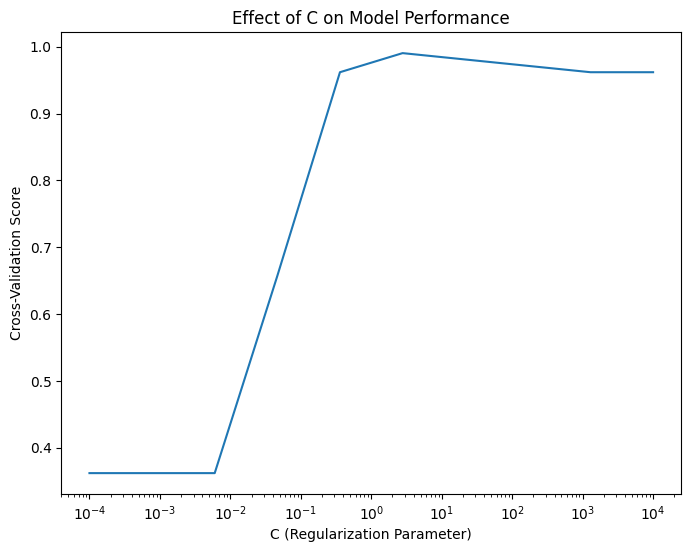

In [17]:
# Akurasi CV SVM RBF untuk 10 nilai C dari 1e-4 hingga 1e4
param_grid_c = {
    'C': np.logspace(-4, 4, 10),
    'kernel': ['rbf']
}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

plt.figure(figsize=(8, 6))
plt.plot(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score'])
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.show()

In [18]:
# Angka di balik kurva (tambahan)
pd.DataFrame({"C": grid_search_c.param_grid['C'],
              "rata-rata akurasi CV": grid_search_c.cv_results_['mean_test_score']}).round(4).T

,0,1,2,3,4,5,6,7,8,9
C,0.0001,0.0008,0.0060,0.0464,0.3594,2.7826,21.5443,166.8101,1291.5497,10000.0000
rata-rata akurasi CV,0.3619,0.3619,0.3619,0.6571,0.9619,0.9905,0.9810,0.9714,0.9619,0.9619


**Interpretasi output.** Kurvanya memiliki bentuk klasik **underfit → optimum → sedikit overfit**:

* Untuk $C\le0.006$, akurasi CV datar di **0.362**. Penalti pelanggaran begitu kecil sehingga SVM praktis memprediksi kelas mayoritas untuk semuanya (versicolor sekitar 36 % dari data latih).
* Akurasi naik tajam melalui $C=0.046$ (0.657) dan $C=0.36$ (0.962) dan mencapai puncak di **$C\approx2.8$ dengan 0.9905**.
* Untuk `C` yang lebih besar, akurasi sedikit menurun: 0.981 pada 21.5, 0.971 pada 167, dan 0.962 mulai 1.292. Margin menjadi terlalu ketat dan mulai mengikuti titik-titik berisik secara individual.
* Bentuk datar-lalu-curam ini menunjukkan mengapa `C` harus dicari pada skala logaritmik.

### Poin Penting
* `C` menukar lebar margin dengan kesalahan latih. Terlalu kecil menyebabkan *underfitting* (0.362), optimumnya di sini sekitar $C\approx2.8$ (0.9905), dan terlalu besar menyebabkan sedikit *overfitting*.
* Grid yang memuat parameter tidak relevan (`degree` untuk linear/RBF) menciptakan pengaturan duplikat, dan yang dilaporkan sebagai terbaik hanyalah yang pertama dari delapan yang seri.
* Akurasi CV model terpilih (0.99) melebih-lebihkan akurasi ujinya (0.93). Gunakan data uji yang disisihkan atau *nested CV*.

## Resep 7.4 — SVM di Ruang Berdimensi Tinggi

**Tujuan.** Menerapkan SVM linear pada dataset "lebar" (1.000 fitur, hanya 700 sampel latih, 50 fitur informatif) dan melihat data melalui proyeksi PCA 2-D.

### Teori

**Intuisi.** SVM sering direkomendasikan untuk data berdimensi tinggi karena kompleksitasnya bergantung pada margin dan jumlah *support vector*, bukan langsung pada jumlah fitur. Namun dimensi tinggi bagaikan pedang bermata dua. Dengan fitur lebih banyak daripada sampel, **hampir setiap pelabelan titik latih dapat dipisahkan oleh sebuah *hyperplane***, termasuk pelabelan yang murni *noise*. Fit sempurna pada data latih menjadi pasti dan tidak berkata apa pun tentang generalisasi.

**Matematika.** *Teorema Cover*: $n$ titik dalam posisi umum di $\mathbb{R}^p$ dapat dipisahkan secara linear dengan **setiap** dari $2^n$ cara yang mungkin jika $n\le p+1$. Di sini $p=1000$ dan $n=700$, sehingga data latih dapat dipisahkan apa pun labelnya. SVM *soft-margin* akan menemukan *hyperplane* pemisah dengan semua $\xi_i=0$, tetapi sebagian besar dari 1.000 koordinat $\mathbf{w}$ mem-fit *noise* dari 950 fitur yang tidak informatif. Generalisasi kemudian bergantung pada seberapa besar margin berasal dari 50 arah informatif dibanding arah *noise*.

`make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0)` menempatkan klaster kelas di subruang informatif 50-D dan menambahkan 950 fitur *noise* Gaussian yang independen. Dengan `n_redundant=0` (dan default `n_repeated=0`), fitur-fitur *noise* sama sekali tidak berhubungan dengan kelas.

**Cara scikit-learn mengimplementasikannya.** `SVC(kernel="linear")` menyelesaikan bentuk dual, sehingga biayanya lebih bergantung pada $n$ (melalui matriks kernel $n\times n$) daripada pada $p$. `LinearSVC` (liblinear) menyelesaikan bentuk primal dan lebih skalabel untuk banyak sampel. Untuk visualisasi, `PCA(n_components=2)` memproyeksikan data ke dua arah dengan variansi terbesar (Bab 3). Dengan 950 fitur *noise* bervariansi sama, arah-arah itu sebagian besar adalah *noise*.

**Asumsi, kelebihan, keterbatasan.**

* Kernel linear biasanya pilihan yang tepat ketika $p\gg n$, karena kernel non-linear justru menambah kapasitas.
* Regularisasi (`C` lebih kecil) dan seleksi fitur sangat penting ketika sebagian besar fitur adalah *noise*.
* Akurasi latih tidak bermakna dalam kondisi ini, jadi selalu evaluasi pada data yang disisihkan.

### Kode

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np

# 1.000 sampel x 1.000 fitur: 50 informatif, 950 murni noise
X, y = make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0, random_state=2024)

# Pembagian 70/30 -> 700 sampel latih / 300 sampel uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [20]:
svm_model = SVC(kernel='linear')

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

styled_report_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


In [21]:
# Akurasi latih dan jumlah support vector (tambahan)
print(f"akurasi latih: {svm_model.score(X_train, y_train):.3f} | akurasi uji: {accuracy:.3f}")
print(f"support vector: {svm_model.n_support_.sum()} dari {len(X_train)} sampel latih")

akurasi latih: 1.000 | akurasi uji: 0.747
support vector: 433 dari 700 sampel latih


**Interpretasi output.**

* SVM linear hanya mencapai akurasi uji **74,7 %** (0.75 setelah dibulatkan), dengan skor F1 per kelas yang mirip (0.765 dan 0.725).
* Pengecekan tambahan mengungkap alasannya: **akurasi latih 1.000**. Sesuai prediksi teorema Cover, 700 titik dalam 1.000 dimensi selalu dapat dipisahkan secara linear, sehingga SVM memisahkan data latih dengan sempurna, termasuk *noise*-nya.
* **433 dari 700** titik latih adalah *support vector*. Porsi *support vector* yang besar adalah tanda peringatan klasik untuk *overfitting* atau struktur kelas yang lemah.
* Selisih 25 poin antara akurasi latih dan uji adalah harga dari 950 fitur *noise*. Seleksi fitur, `C` yang lebih kecil, atau lebih banyak sampel adalah solusinya.

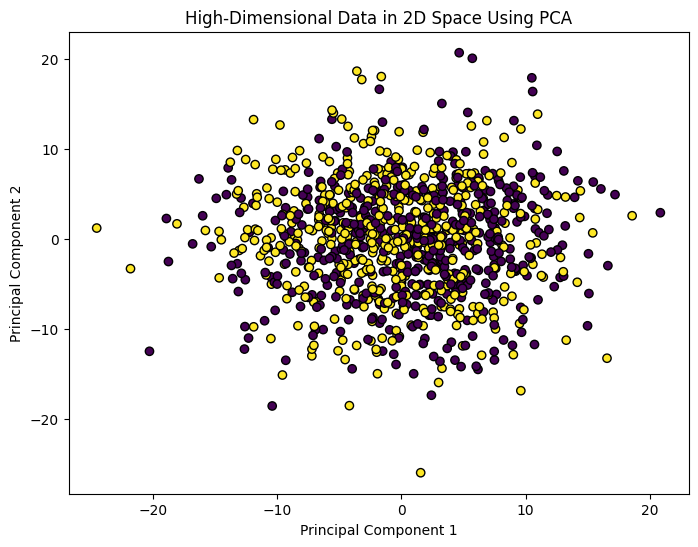

In [22]:
from sklearn.decomposition import PCA

# Proyeksikan ke-1.000 sampel ke 2 komponen utama teratas
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', marker='o')
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [23]:
# Variansi yang ditangkap proyeksi 2-D (tambahan)
print("explained variance ratio:", pca.explained_variance_ratio_.round(4),
      "| total:", round(pca.explained_variance_ratio_.sum(), 4))

explained variance ratio: [0.0245 0.0212] | total: 0.0457


**Interpretasi output.** Proyeksinya berupa satu awan bulat tempat **kedua kelas (ungu dan kuning) bercampur sepenuhnya**. Mungkin ada sedikit kecenderungan satu kelas lebih ke kiri, tetapi sama sekali tidak menyerupai pemisahan. Pengecekan tambahan menjelaskan alasannya: kedua komponen hanya menangkap **4,6 %** dari total variansi (2,4 % + 2,1 %). Dalam 1.000 dimensi yang sebagian besar berupa *noise* independen, tidak ada sekumpulan kecil arah yang mendominasi, dan sinyal kelas berada di subruang 50-D yang tidak dapat ditampilkan dua sumbu PCA. Proyeksi 2-D yang tampak buruk tidak berarti dataset tidak dapat dipelajari (SVM tetap mencapai 75 %), hanya bahwa strukturnya tidak dua dimensi.

### Poin Penting
* Ketika $p\ge n$, data latih selalu dapat dipisahkan secara linear (teorema Cover). Di sini akurasi latih 1.000 tetapi akurasi uji hanya 0.747.
* 433 dari 700 titik menjadi *support vector*, gejala struktur yang lemah dan berisik.
* Tampilan PCA 2-D hanya menangkap 4,6 % variansi dan tidak menunjukkan pemisahan kelas. Struktur berdimensi tinggi memerlukan alat lain (seleksi fitur, LDA, t-SNE).

## Resep 7.5 — Mengevaluasi Model SVM

**Tujuan.** Mengevaluasi SVM linear pada Breast Cancer dengan laporan klasifikasi dan kurva ROC, yang memerlukan pengubahan skor SVM menjadi peluang.

### Teori

**Intuisi.** SVM menghasilkan jarak bertanda ke *hyperplane*, $f(\mathbf{x})$, bukan peluang. Untuk kurva ROC, yang penting hanyalah *peringkat* skor, sehingga $f(\mathbf{x})$ sendiri sudah cukup. scikit-learn juga dapat mengkalibrasi skor itu menjadi peluang dengan **Platt scaling**, yang dilakukan oleh `probability=True`.

**Matematika.** Platt scaling mem-fit regresi logistik satu dimensi pada skor SVM,
$$\hat P(y=1\mid\mathbf{x})=\frac{1}{1+\exp\big(A\,f(\mathbf{x})+B\big)},$$
dengan $A,B$ dipelajari melalui *maximum likelihood* pada skor yang dihasilkan *cross-validation* internal 5-fold (agar kalibrasi tidak di-fit pada skor dari titik-titik yang dipakai melatih SVM). Kurva ROC dan AUC kemudian dihitung persis seperti di Resep 6.5: TPR $=TP/(TP+FN)$ terhadap FPR $=FP/(FP+TN)$ di semua ambang, dan AUC = peluang sampel positif acak diperingkat di atas sampel negatif acak.

**Cara scikit-learn mengimplementasikannya.** `SVC(kernel="linear", probability=True)` menjalankan *cross-validation* internal tambahan selama `fit`, sehingga pelatihan beberapa kali lebih lambat. `predict_proba` kemudian mengembalikan peluang yang terkalibrasi. Peluang ini sesekali bisa tidak sesuai dengan `predict`, yang memakai tanda $f(\mathbf{x})$. Jika hanya peringkat yang dibutuhkan, `decision_function` lebih cepat dan sepenuhnya konsisten. `roc_curve` dan `auc` dipakai seperti sebelumnya.

**Asumsi, kelebihan, keterbatasan.**

* Platt scaling mengasumsikan hubungan sigmoid antara skor dan peluang. Metode ini bekerja baik untuk SVM, tetapi menambah keacakan (*fold* CV internal) dan biaya.
* SVM linear tanpa penskalaan pada Breast Cancer konvergen lambat, karena libsvm kesulitan dengan fitur yang rentangnya mencakup beberapa orde besaran.

### Kode

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report, roc_curve, auc
import pandas as pd
import matplotlib.pyplot as plt

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Pembagian 70/30 -> 398 tumor latih / 171 tumor uji (tanpa penskalaan)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [25]:
# SVM linear dengan peluang hasil Platt scaling (menambah CV internal 5-fold)
svm_model = SVC(kernel='linear', probability=True)

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_report_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


> **Catatan:** Sel buku mencetak `Accuracy: 0.75`, tetapi **angka ini bukan milik model ini**. Sel tersebut tidak pernah menghitung ulang `accuracy`, sehingga yang tercetak adalah nilai sisa dari Resep 7.4 (SVM dengan 1.000 fitur). Kodenya dipertahankan persis seperti yang diterbitkan. Sel berikutnya menghitung akurasi yang benar untuk model ini, yang juga sesuai dengan baris `accuracy` pada laporan di atas.

In [26]:
from sklearn.metrics import accuracy_score

# Akurasi yang benar untuk model INI, beserta support vector-nya (tambahan)
print(f"Akurasi sebenarnya SVM Breast Cancer: {accuracy_score(y_test, y_pred):.3f}")
print("support vector per kelas [malignant, benign]:", svm_model.n_support_)

Akurasi sebenarnya SVM Breast Cancer: 0.947
support vector per kelas [malignant, benign]: [18 17]


**Interpretasi output.**

* Akurasi uji yang sebenarnya adalah **0.947** (162/171), bukan 0.75 yang tercetak di atas.
* Tumor ganas (kelas 0) ditemukan dengan *recall* **0.940** (63 dari 67) dan *precision* 0.926. Tumor jinak memiliki *recall* 0.952 dan *precision* 0.961.
* Hanya **35 support vector** (18 ganas, 17 jinak) dari 398 tumor latih yang mendefinisikan batas, solusi yang jauh lebih *sparse* daripada 433/700 pada masalah berdimensi tinggi yang berisik. Ini menandakan struktur kelas yang bersih dan terpisah dengan baik.

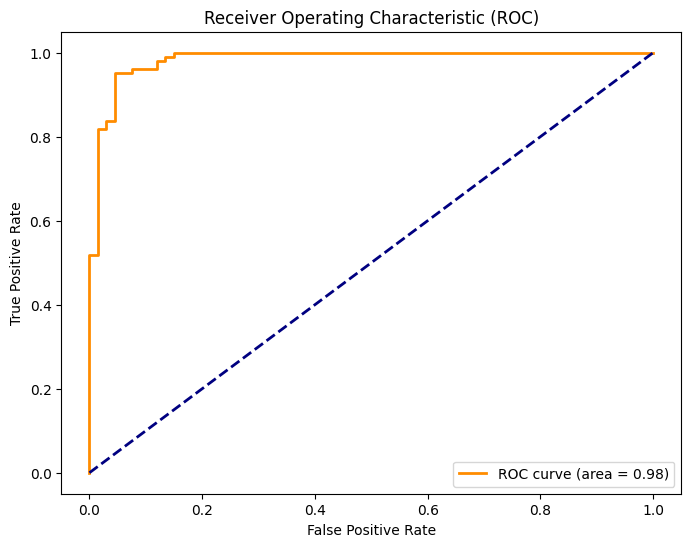

In [27]:
# Kurva ROC dari peluang kelas jinak hasil Platt scaling
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Interpretasi output.** Kurva ROC naik dengan curam. Sekitar separuh tumor jinak dikenali tanpa *false positive*, TPR melewati 0,95 pada FPR sekitar 0,05, dan mencapai 1,0 pada FPR sekitar 0,15. **AUC bernilai 0.98**, sedikit di bawah 0.99 milik regresi logistik di Resep 6.5 pada pembagian data yang sama. Kedua model memeringkat tumor hampir sempurna, dan kesalahan yang tersisa berasal dari letak ambang, bukan dari pemisahan yang buruk.

### Poin Penting
* `probability=True` menambahkan Platt scaling (sigmoid yang di-fit pada skor SVM dari CV internal). Ini diperlukan untuk `predict_proba` tetapi memperlambat pelatihan.
* Kode buku mencetak akurasi basi (0.75). Akurasi sebenarnya 0.947: selalu periksa bahwa metrik yang tercetak memang dihitung untuk model yang sedang dibahas.
* SVM linear mencapai AUC 0.98 dengan hanya 35 *support vector*.

## Resep 7.6 — Latihan Praktis SVM

**Tujuan.** (1) Membangun SVM linear dasar pada Iris. (2) Men-*tuning* SVM pada Breast Cancer dengan *grid search*. (3) Memvisualisasikan batas keputusan SVM RBF pada dataset sintetis 2-D.

### Teori

* **Latihan 1** mengulang `SVC` linear dari Resep 7.1 pada pembagian data yang sama, sehingga hasilnya seharusnya identik. SVM menyelesaikan masalah konveks dengan solusi yang unik.
* **Latihan 2** menjalankan grid 27 pengaturan dari Resep 7.3 pada data Breast Cancer yang **tidak diskalakan**. Tanpa penskalaan, jarak pada kernel RBF didominasi fitur-fitur terbesar (area bernilai ratusan atau ribuan), dan kernel polinomial memangkatkan nilai-nilai besar itu, sehingga kernel linear cenderung menang. Grid ini juga yang paling lama dijalankan di bab ini (sekitar satu menit), karena kernel poly dan linear konvergen lambat pada data yang tidak diskalakan.
* **Latihan 3** menjadi pembanding Latihan 3 di Bab 6. Dataset 2-D yang sama, dengan dua klaster per kelas, di-fit dengan kernel **RBF**, yang fungsi keputusannya $\sum_i\alpha_iy_i\exp(-\gamma\lVert\mathbf{x}_i-\mathbf{x}\rVert^2)+b$ dapat melengkung mengitari klaster alih-alih terbatas pada garis lurus.

### Kode — Latihan 1: Membangun Classifier SVM Sederhana

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(report)

Accuracy: 0.93
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.91      0.83      0.87        12
           2       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.92      0.92        45
weighted avg       0.93      0.93      0.93        45



**Interpretasi output.** Akurasi **0.93** dengan angka per kelas yang persis sama seperti Resep 7.1 (setosa 1.00/1.00, *recall* versicolor 0.83, *precision* virginica 0.88). Masalah konveks yang sama pada data yang sama memiliki satu solusi, sehingga hasilnya sepenuhnya dapat direproduksi.

### Kode — Latihan 2: Tuning Parameter SVM dengan Grid Search

In [29]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Grid 27 pengaturan yang sama seperti Resep 7.3, pada fitur tanpa penskalaan
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)


best_model = SVC(**grid_search.best_params_)
best_model.fit(X_train, y_train)

y_pred_best = best_model.predict(X_test)

accuracy_best = accuracy_score(y_test, y_pred_best)
report_best = classification_report(y_test, y_pred_best)
print(f"Best Model Accuracy: {accuracy_best:.2f}")
print("Best Model Classification Report:")
print(report_best)

Best Model Accuracy: 0.95
Best Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        67
           1       0.96      0.95      0.96       104

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



In [30]:
# Solusi resmi tidak mencetak pengaturan pemenang (tambahan)
print("parameter terbaik:", grid_search.best_params_, "| akurasi CV terbaik:", round(grid_search.best_score_, 4))

parameter terbaik: {'C': 1, 'degree': 2, 'kernel': 'linear'} | akurasi CV terbaik: 0.9623


**Interpretasi output.** Sel tambahan menunjukkan bahwa *grid search* memilih **kernel linear dengan `C=1`** (akurasi CV 0.962; `degree=2` tidak relevan untuk kernel linear dan muncul hanya karena berada pertama di grid). Pada data uji, model mencapai **0.95**, dengan *recall* ganas 0.94 dan *recall* jinak 0.95, sama dengan SVM linear di Resep 7.5 yang juga memakai `C=1`. Seperti yang diharapkan pada data tanpa penskalaan, kernel linear mengalahkan kernel RBF dan polinomial.

### Kode — Latihan 3: Memvisualisasikan Batas Keputusan SVM

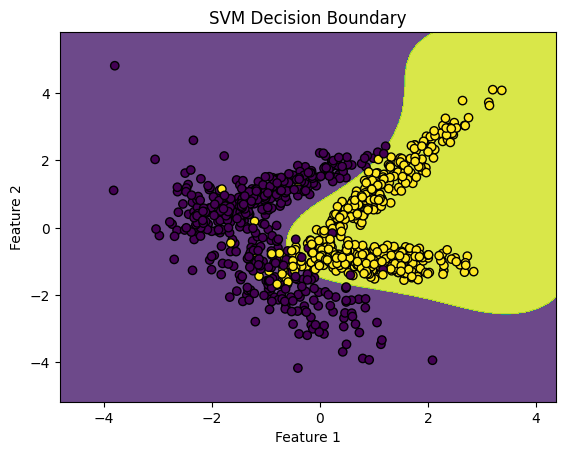

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Dataset 2-D dengan dua klaster per kelas yang sama seperti Bab 6, Latihan 3
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Kelas prediksi di setiap titik grid
Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [32]:
# Akurasi uji SVM RBF (tambahan; model logistik linear Bab 6 mencetak 0.897 pada pembagian ini)
print(f"akurasi uji: {svm_model.score(X_test, y_test):.3f} | support vector: {svm_model.n_support_.sum()}")

akurasi uji: 0.977 | support vector: 118


**Interpretasi output.** Berbeda dengan batas regresi logistik yang lurus di Bab 6, batas RBF **melengkung mengitari kelas kuning**: wilayah membulat di sebelah kanan yang membungkus kedua klaster kuning yang memanjang dan mengikuti celah antara klaster itu dan titik-titik ungu, sementara segala sesuatu yang jauh dari data kuning menjadi ungu secara default. Pengecekan tambahan menunjukkan akurasi uji **0.977** dengan 118 *support vector*, naik dari 0.897 untuk model logistik linear pada pembagian data yang sama. Inilah *kernel trick* dalam praktik: batas non-linear menangkap struktur yang tidak dapat ditangkap batas linear.

### Poin Penting
* Data yang sama + masalah SVM konveks yang sama = jawaban yang sama (Latihan 1 mereproduksi Resep 7.1 dengan tepat).
* Pada data Breast Cancer tanpa penskalaan, *grid search* memilih kernel linear (`C=1`, uji 0.95). Penskalaan diperlukan sebelum kernel RBF atau polinomial bisa bersaing.
* Kernel RBF melengkung mengitari kelas berklaster banyak dan menaikkan akurasi uji 2-D dari 0.897 (linear) menjadi 0.977.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 7.1 Pengantar SVM | Klasifikasi margin maksimum, *soft margin*, regresi ε-insensitive | `SVC(kernel="linear")`, `SVR`, `DecisionBoundaryDisplay` | 93,3 % pada Iris dengan hanya 21 *support vector*. SVR pada label berurutan memberi $R^2$ 0,72. |
| 7.2 Fungsi Kernel | *Kernel trick*: linear, polinomial, RBF | `SVC(kernel=...)` | Poly 95,6 % > linear 93,3 % > RBF 91,1 % (1–2 bunga). Dengan fitur sepal saja, semua kernel turun ke sekitar 80 %. |
| 7.3 *Tuning* Parameter SVM | *Grid search* `C`/kernel/degree, efek `C` | `GridSearchCV` | Delapan pengaturan seri di CV 0.9905. Kurva `C`: *underfit* (0.362) → optimum (≈2,8) → sedikit *overfit*. |
| 7.4 SVM di Dimensi Tinggi | $p>n$ ⇒ selalu dapat dipisahkan (Cover) | `SVC`, `make_classification`, `PCA` | Latih 1.000 vs uji 0.747. PCA 2-D hanya menangkap 4,6 % variansi. |
| 7.5 Mengevaluasi Model SVM | Platt scaling, ROC/AUC | `SVC(probability=True)`, `roc_curve`, `auc` | Akurasi sebenarnya 0.947 (buku mencetak nilai basi 0.75), AUC 0.98. |
| 7.6 Latihan Praktis | Reproduktibilitas, *tuning* pada data tanpa penskalaan, batas RBF | `SVC`, `GridSearchCV` | Kernel linear menang pada data tanpa penskalaan. RBF menaikkan akurasi 2-D dari 0.897 menjadi 0.977. |

**Kaitan dengan Bab 8.** SVM bergantung pada jarak dan margin, sehingga memerlukan fitur yang diskalakan dan *tuning* yang cermat, serta kurang skalabel untuk dataset besar. **Model berbasis pohon** (Bab 8) menempuh jalur yang sama sekali berbeda. Model ini memecah data dengan aturan ambang sederhana, **tidak terpengaruh penskalaan fitur**, menangani interaksi non-linear secara alami, dan menjadi sangat kuat ketika banyak pohon digabungkan menjadi **ensemble** (*random forest*, *gradient boosting*, *stacking*). Alat *grid search* dan evaluasi dari bab ini dapat langsung dipakai di sana.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 7.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Support Vector Machines (formulasi, kernel, multikelas, skor dan peluang): <https://scikit-learn.org/1.5/modules/svm.html>
* scikit-learn API — `SVC`: <https://scikit-learn.org/1.5/modules/generated/sklearn.svm.SVC.html>
* scikit-learn API — `DecisionBoundaryDisplay`: <https://scikit-learn.org/1.5/modules/generated/sklearn.inspection.DecisionBoundaryDisplay.html>
* scikit-learn User Guide — Probability calibration (Platt scaling): <https://scikit-learn.org/1.5/modules/calibration.html>
* Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273–297.
* Cover, T. M. (1965). Geometrical and statistical properties of systems of linear inequalities with applications in pattern recognition. *IEEE Transactions on Electronic Computers*, EC-14(3), 326–334.